In [85]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import cross_val_score

In [86]:
# Baca file CSV
df = pd.read_csv('diabetes.csv')

# Tampilkan DataFrame untuk memastikan telah dibaca dengan benar
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [87]:
df.describe(include="all")

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [88]:
# Tampilkan informasi umum tentang dataset
print("\nInformasi dataset:")
df.info()


Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [89]:
# Cek data duplikat
print("Jumlah data duplikat:", df.duplicated().sum())
df = df.drop_duplicates()

# Simpan salinan data asli
df_zero = df.copy()

Jumlah data duplikat: 0


In [90]:
# Membersihkan data yang bernilai 0
zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
print("Jumlah nilai 0 per kolom:\n", (df[zero_cols] == 0).sum())
df[zero_cols] = df[zero_cols].replace(0, np.nan)

# Simpan versi NaN
df_nan = df.copy()

Jumlah nilai 0 per kolom:
 Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [91]:
# Cek missing values
print("\nMissing values per fitur:")
missing_summary = pd.DataFrame({"Jumlah NaN": df.isnull().sum(), "Persen (%)": (df.isnull().mean() * 100).round(1)})
print(missing_summary)
df.head()


Missing values per fitur:
                          Jumlah NaN  Persen (%)
Pregnancies                        0         0.0
Glucose                            5         0.7
BloodPressure                     35         4.6
SkinThickness                    227        29.6
Insulin                          374        48.7
BMI                               11         1.4
DiabetesPedigreeFunction           0         0.0
Age                                0         0.0
Outcome                            0         0.0


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50,1
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31,0
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


In [92]:
# Untuk mengisi data yang berisi NaN dengan nulai median berdasarkan dari kategori outcome
for col in zero_cols:
    df[col] = df[col].fillna(df.groupby('Outcome')[col].transform('median'))

In [93]:
# Cek missing values setelah mengganti isi nilai
print("\nMissing values per fitur:")
print(df.isnull().sum())


Missing values per fitur:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [94]:
# Tampilkan DataFrame untuk memastikan data telah bersih
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,169.5,33.6,0.627,50,1
1,1,85.0,66.0,29.0,102.5,26.6,0.351,31,0
2,8,183.0,64.0,32.0,169.5,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


In [95]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,121.677083,72.389323,29.089844,141.753906,32.434635,0.471876,33.240885,0.348958
std,3.369578,30.464161,12.106039,8.890820,89.100847,6.880498,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.750000,64.000000,25.000000,102.500000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,28.000000,102.500000,32.050000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,169.500000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


Visualisasi dan Analisis data

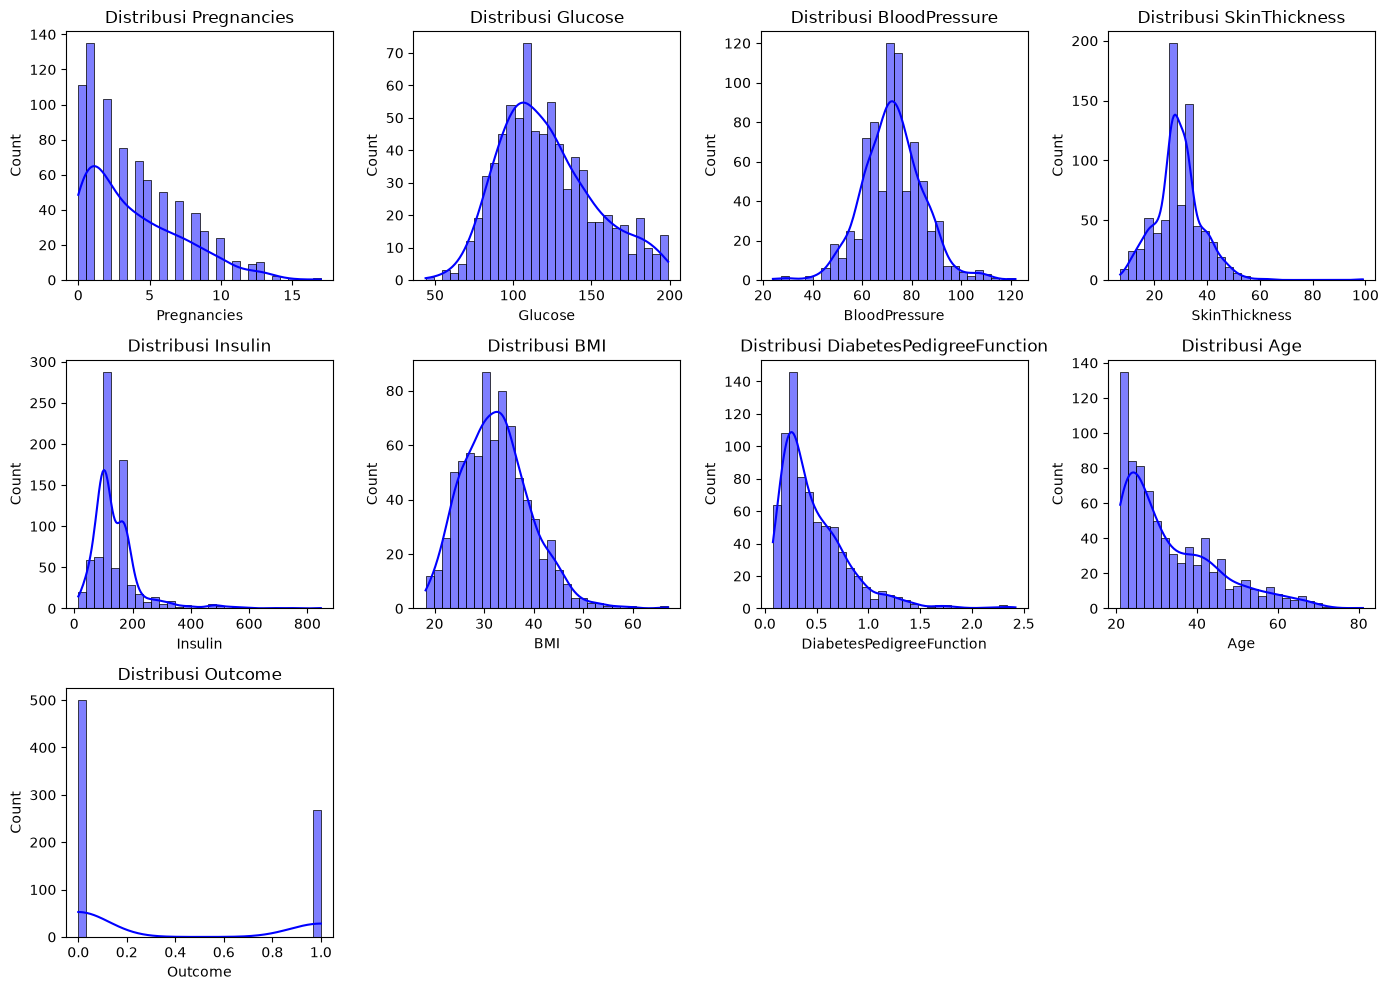

In [96]:
# Distribusi fitur numerik
num_features = df.select_dtypes(include=[np.number])
plt.figure(figsize=(14, 10))
for i, column in enumerate(num_features.columns, 1):
    plt.subplot(3, 4, i)
    sns.histplot(df[column], bins=30, kde=True, color='blue') 
    plt.title(f'Distribusi {column}')
plt.tight_layout()
plt.show()

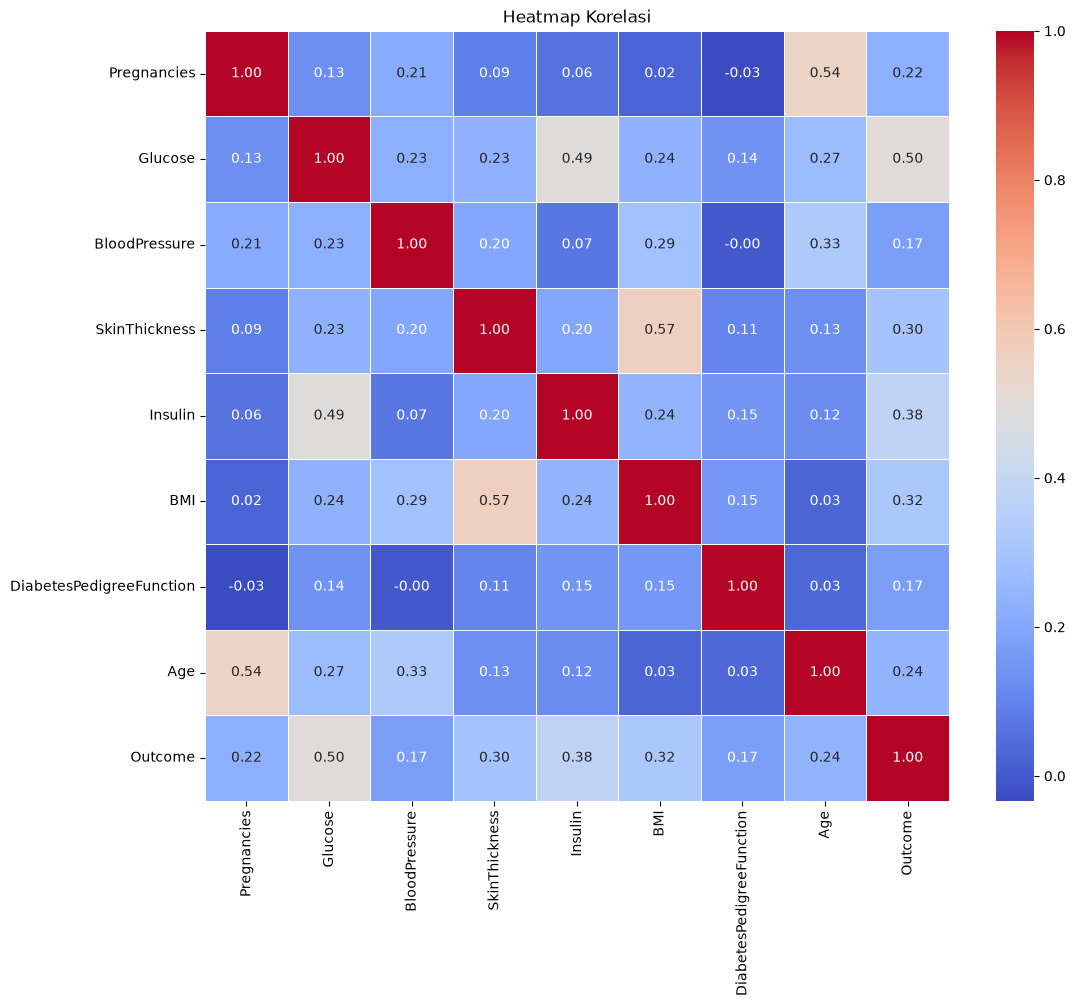

In [97]:
# Heatmap korelasi untuk fitur numerik
plt.figure(figsize=(12, 10))
correlation_matrix = num_features.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Heatmap Korelasi')
plt.show()

C:\Users\HP VICTUS\AppData\Local\Temp\ipykernel_26576\1948545625.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='Outcome', data=df, palette='viridis', legend=False)


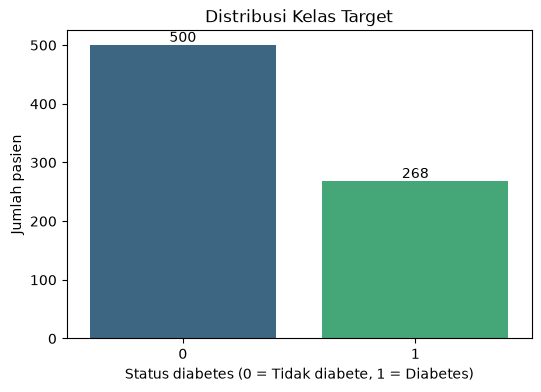

In [98]:
# Visualisasi distribusi variabel target
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='Outcome', data=df, palette='viridis', legend=False)
plt.title('Distribusi Kelas Target')
plt.xlabel('Status diabetes (0 = Tidak diabete, 1 = Diabetes)') 
plt.ylabel('Jumlah pasien') 

# Menampilkan angka di atas setiap bar
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.show()

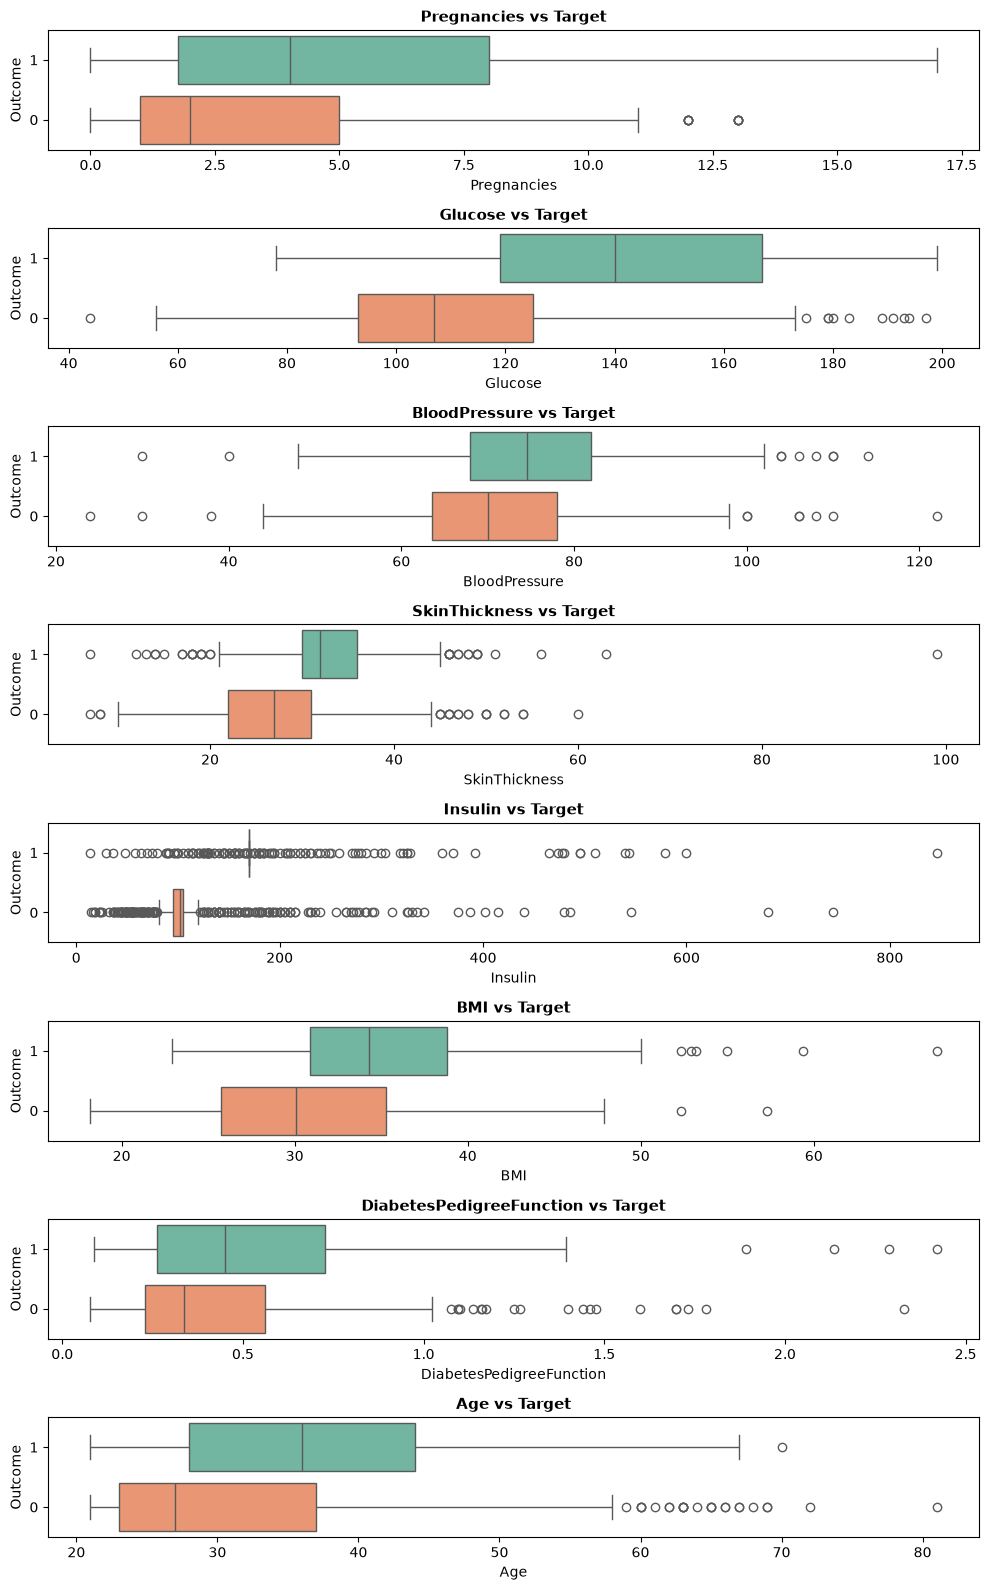

In [99]:
# Visualisasi Outlier dengan Boxplot dan membandingkan antara fitur dengan target
numeric_cols = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

data_plot = df.copy()
data_plot['Outcome'] = data_plot['Outcome'].astype(str) # isi dengan target yang ingin dijadikan parameter perbandingan

plt.figure(figsize=(10, 16))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(8, 1, i)
    sns.boxplot(
        x=col,
        y='Outcome',
        hue='Outcome',
        data=data_plot,
        orient='h',
        palette='Set2',
        legend=False
    )
    plt.title(f'{col} vs Target', fontsize=11, fontweight='bold')
    plt.xlabel(col)
    plt.ylabel('Outcome')

plt.tight_layout()
plt.show()

Feature scalling

In [100]:
# Buat instance StandardScaler
scaler = StandardScaler()


features_to_scale = [col for col in df.columns if col != 'Outcome']

# Lakukan scaling pada fitur-fitur tersebut
df[features_to_scale] = scaler.fit_transform(df[features_to_scale])


df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,0.639947,0.864625,-0.032180,0.665181,0.311604,0.169483,0.468492,1.425995,1
1,-0.844885,-1.204727,-0.528124,-0.010112,-0.440843,-0.848549,-0.365061,-0.190672,0
2,1.233880,2.014265,-0.693438,0.327535,0.311604,-1.328478,0.604397,-0.105584,1
3,-0.844885,-1.073339,-0.528124,-0.685405,-0.536303,-0.630399,-0.920763,-1.041549,0
4,-1.141852,0.503310,-2.677212,0.665181,0.294758,1.551096,5.484909,-0.020496,1


Data Splitting

In [101]:
# Pisahkan fitur (X) dan target (y)
X = df.drop(columns=['Outcome'])
y = df['Outcome']

# Split data menjadi set pelatihan dan set uji
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Tampilkan bentuk set pelatihan dan set uji untuk memastikan split
print(f"Training set shape: X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Test set shape: X_test={X_test.shape}, y_test={y_test.shape}")

Training set shape: X_train=(614, 8), y_train=(614,)
Test set shape: X_test=(154, 8), y_test=(154,)


Model Training

In [102]:
# Pelatihan Model
LogReg_A = LogisticRegression(max_iter=1000, random_state=42).fit(X_train, y_train)
RandForest_A = RandomForestClassifier(random_state=42).fit(X_train, y_train)
GradBoost_A = GradientBoostingClassifier(random_state=42).fit(X_train, y_train)

print("Model training selesai.")

Model training selesai.


Model Evaluation

In [103]:
# Fungsi untuk mengevaluasi dan mengembalikan hasil sebagai kamus
def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    results = {
        'Confusion Matrix': cm,
        'True Positive (TP)': tp,
        'False Positive (FP)': fp,
        'False Negative (FN)': fn,
        'True Negative (TN)': tn,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred)
    }
    return results

# Mengevaluasi setiap model dan mengumpulkan hasilnya
results = {
    'Logistic Regression': evaluate_model(LogReg_A, X_test, y_test),
    'Random Forest': evaluate_model(RandForest_A, X_test, y_test),
    'Gradient Boosting': evaluate_model(GradBoost_A, X_test, y_test)
}

# Buat DataFrame untuk meringkas hasil
summary_df = pd.DataFrame(columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score'])

# Isi DataFrame dengan hasil
rows = []
for model_name, metrics in results.items():
    rows.append({
        'Model': model_name,
        'Accuracy': metrics['Accuracy'],
        'Precision': metrics['Precision'],
        'Recall': metrics['Recall'],
        'F1-Score': metrics['F1-Score']
    })

# Konversi daftar kamus ke DataFrame
summary_df = pd.DataFrame(rows)

# Tampilkan DataFrame
print(summary_df)

                 Model  Accuracy  Precision    Recall  F1-Score
0  Logistic Regression  0.772727   0.692308  0.654545  0.672897
1        Random Forest  0.883117   0.813559  0.872727  0.842105
2    Gradient Boosting  0.870130   0.807018  0.836364  0.821429


Overfitting & Underfitting Handling

In [104]:
# Menggunakan cross-validation dengan 5 fold pada model Random Forest
cross_val_scores = cross_val_score(RandForest_A, X_train, y_train, cv=5, scoring='accuracy')

# Menampilkan hasil cross-validation
print(f'Cross-Validation Accuracy: {cross_val_scores.mean():.4f}')

Cross-Validation Accuracy: 0.8877


Hyperparameter Tuning

In [105]:
tuned_results = {}

# Daftar model dan hyperparameter yang akan diuji
models_to_tune = {
    "Logistic Regression": (
        LogisticRegression(max_iter=1000, random_state=42), 
        {'C': [0.01, 0.1, 1, 10]}
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=42), 
        {'n_estimators': [100, 200, 300], 'max_depth': [3, 5, 7], 'min_samples_leaf': [2, 5]}
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=42), 
        {'n_estimators': [100, 150], 'learning_rate': [0.01, 0.05, 0.1], 'max_depth': [2, 3, 5]}
    )
}

print("Sedang memproses Hyperparameter Tuning...")

# Proses iterasi tuning model menggunakan GridSearchCV
for name, (model, params) in models_to_tune.items():
    
    # Inisialisasi dan fit GridSearchCV
    grid = GridSearchCV(model, params, cv=5, scoring='accuracy', n_jobs=-1)
    grid.fit(X_train, y_train)
    
    # Hitung akurasi pada data Train dan Test
    train_acc = grid.score(X_train, y_train)
    test_acc = grid.score(X_test, y_test)
    gap = train_acc - test_acc
    
    # Simpan hasil metrik ke dictionary 'tuned_results'
    tuned_results[name] = {
        'Best Params': grid.best_params_,
        'Train Accuracy': train_acc,
        'Test Accuracy': test_acc,
        'Gap': gap
    }

print("Proses Tuning Selesai!\n")

# TAMPILKAN RANGKUMAN TABEL

comparison_rows = []
for name, metrics in tuned_results.items():
    comparison_rows.append({
        'Model': name,
        'Best Hyperparameters': str(metrics['Best Params']),
        'Training Accuracy (Tuned)': f"{metrics['Train Accuracy']:.4f}",
        'Test Accuracy (Tuned)': f"{metrics['Test Accuracy']:.4f}",
        'Gap (Train - Test)': f"{metrics['Gap']:.4f}",
        'Status': 'Good Fit / Stabil' if -0.05 <= metrics['Gap'] <= 0.08 else ('Indikasi Overfitting' if metrics['Gap'] > 0.08 else 'Indikasi Underfitting')
    })

summary_tuning_df = pd.DataFrame(comparison_rows)
display(summary_tuning_df)

Sedang memproses Hyperparameter Tuning...
Proses Tuning Selesai!



,Model,Best Hyperparameters,Training Accuracy (Tuned),Test Accuracy (Tuned),Gap (Train - Test),Status
0,Logistic Regression,{'C': 0.01},0.7785,0.7857,-0.0072,Good Fit / Stabil
1,Random Forest,"{'max_depth': 7, 'min_samples_leaf': 5, 'n_est...",0.9414,0.8766,0.0647,Good Fit / Stabil
2,Gradient Boosting,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti...",0.9658,0.8766,0.0892,Indikasi Overfitting
